In [2]:
!pip -q install ultralytics

In [3]:
import cv2
import matplotlib.pyplot as plt

from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리

# YOLO :: (딥러닝 모델) 이미지 속 물체의 종류/위치를 탐지하는 모델 (학습이 완료된 모델)
from ultralytics import YOLO
from urllib.request import urlretrieve  # 인터넷 파일 저장

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab_AI 영상처리
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


크기: (1080, 810, 3)


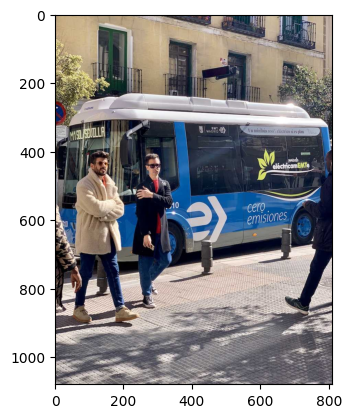

In [6]:
# (객체 탐지에 사용할) 이미지 준비
Save_Path = Path('/content/drive/MyDrive/Colab_AI 영상처리/picture/bus.jpg')
if not Save_Path.exists():
  urlretrieve(
      "https://ultralytics.com/images/bus.jpg",
      str(Save_Path)
  )

img = cv2.imread(str(Save_Path))
print('크기:', img.shape)

img_rgb = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)
plt.imshow(img_rgb)
plt.show()

In [7]:
# YOLO 모델 불러오기 (학습 완료된 모델)
model = YOLO('yolo11n.pt')

In [15]:
# YOLO 모델로 물체 탐지 진행
results = model.predict(
    source = img,     # 분석할 이미지
    conf = 0.5,       # 신뢰도 기준 (50% 정도 확실한 결과만 탐지)
    verbose = False   # 실행로그 출력 여부
)

print(results)

[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: None
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'c

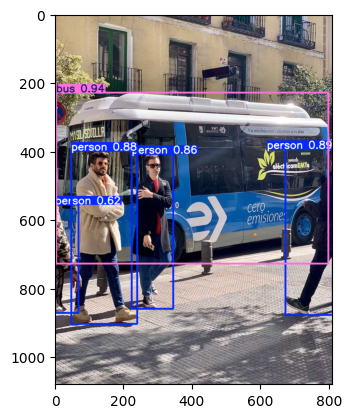

물체의 개수: 5


In [16]:
# 이미지 분석 결과
result = results[0]

rs_img = result.plot()

rs_rgb = cv2.cvtColor(
    rs_img,
    cv2.COLOR_RGB2BGR
)
plt.imshow(rs_rgb)
plt.show()

print('물체의 개수:', len(result.boxes))